# Pancreatic islets
### Gene gradients in a pretrained scVI model

We use the mouse CELLxGENE Census model to examine changes in predicted gene expression
between normal and diabetic islet cells. We first look at **Ins1** in beta cells and
**Gcg** in alpha cells, then rank genes by the directions of their gradients.
We also show the gradients as streamlines, then extend the display to UMAP.

This notebook uses a fresh, reproducible sample from the paper's model and data.


In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from sklearn.decomposition import PCA
from umap import UMAP

from _scvi import load_census, gene_gradient, mean_alignment
from gradient_projection import project_gradients
from _streamlines import smooth_field

torch.set_num_threads(4)

plt.style.use('default')
plt.rcParams.update({
    'figure.dpi': 140, 'font.family': 'sans-serif',
    'font.sans-serif': ['IBM Plex Sans', 'DejaVu Sans'],
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'normal',
    'axes.labelsize': 10, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': '#D9D4CE', 'axes.linewidth': .6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False,
    'text.color': '#242322', 'axes.labelcolor': '#68615D',
    'xtick.color': '#68615D', 'ytick.color': '#68615D',
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'xtick.major.width': .5, 'ytick.major.width': .5,
    'legend.frameon': False, 'savefig.bbox': 'tight', 'savefig.facecolor': 'white',
})

disease_names = ['Normal', 'Type 2 diabetes']
disease_values = ['normal', 'type 2 diabetes mellitus']
disease_colors = ['#487FA9', '#CB805A']

## Load the model and cells

Place the [minified atlas](https://cellxgene-contrib-public.s3.amazonaws.com/models/scvi/2024-02-12/mus_musculus/adata_minified.h5ad)
in `data/census/` and the matching [model](https://cellxgene-contrib-public.s3.amazonaws.com/models/scvi/2024-02-12/mus_musculus/model.pt)
in `checkpoints/census/`. These are the **2024-02-12 mouse** files.

The model was trained on about 5.7 million cells. We use its saved 50-dimensional
representations and keep the decoder fixed. The loader checks the order of the
8,000 genes and matches each cell's batch to the model by name.


In [2]:
atlas_path = Path('data/census/adata_minified.h5ad')
model_path = Path('checkpoints/census/model.pt')
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Primary islet cells labelled normal or type 2 diabetes.
decoder, cells, genes = load_census(
    atlas_path, model_path, n_cells=10_000, seed=42, device=device,
)
z = cells['latents']

cell_names = {
    'type B pancreatic cell': 'Beta',
    'pancreatic A cell': 'Alpha',
    'pancreatic D cell': 'Delta',
    'pancreatic PP cell': 'PP',
    'hematopoietic cell': 'Hematopoietic',
}
cell_labels = pd.Series(cells['cell_type']).replace(cell_names)
condition = pd.Series(cells['disease']).replace(dict(zip(disease_values, disease_names)))
counts = pd.crosstab(cell_labels, condition).reindex(columns=disease_names, fill_value=0)
counts.index.name = 'Cell type'
counts.columns.name = None
counts['Total'] = counts.sum(axis=1)
counts.sort_values('Total', ascending=False)

,Normal,Type 2 diabetes,Total
Cell type,,,
Beta,2717,1714,4431
Alpha,793,805,1598
Hematopoietic,95,999,1094
Delta,375,549,924
pancreatic stellate cell,251,233,484
pancreatic endocrine cell,159,290,449
endothelial cell,229,189,418
PP,113,160,273
pancreatic ductal cell,92,155,247


## The islet representation

These two views use the same PCA coordinates. Cell identity accounts for much of
the variation, so we compare normal and diabetic cells **within a cell type** below.


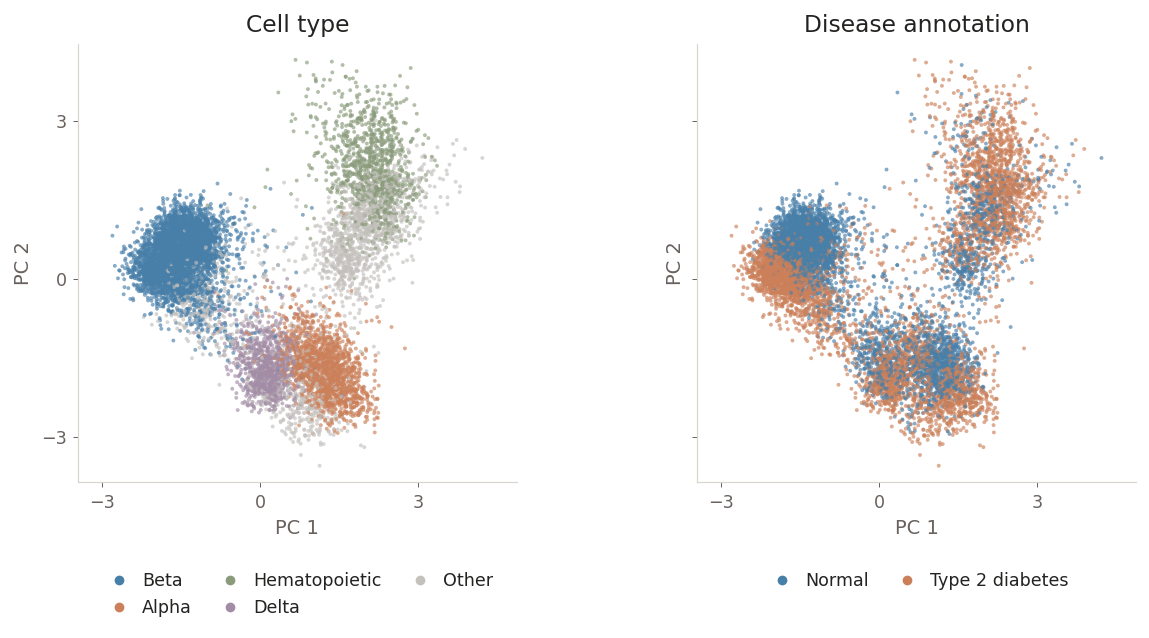

In [3]:
pca = PCA(n_components=2, svd_solver='full')
xy = pca.fit_transform(z)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), layout='constrained', sharex=True, sharey=True)

common_types = cell_labels.value_counts().head(4).index
palette = ['#487FA9', '#CB805A', '#8A9B7B', '#A38DA6']
# Mix the drawing order so no group is consistently drawn on top.
order = np.random.default_rng(42).permutation(len(xy))
type_colors = cell_labels.map(dict(zip(common_types, palette))).fillna('#C4C1BD').to_numpy()
group_colors = np.where(cells['disease'] == disease_values[0], *disease_colors)
for ax, colors in zip(axes, [type_colors, group_colors]):
    ax.scatter(*xy[order].T, c=colors[order], s=4, alpha=.65, linewidths=0)

type_handles = [Line2D([], [], marker='o', linestyle='none', color=color, markersize=4, label=name)
                for name, color in zip(common_types, palette)]
if (~cell_labels.isin(common_types)).any():
    type_handles.append(Line2D([], [], marker='o', linestyle='none', color='#C4C1BD', markersize=4, label='Other'))
disease_handles = [Line2D([], [], marker='o', linestyle='none', color=color, markersize=4, label=name)
                   for name, color in zip(disease_names, disease_colors)]
for ax, title, handles in zip(axes, ['Cell type', 'Disease annotation'], [type_handles, disease_handles]):
    centre = (xy.min(axis=0) + xy.max(axis=0)) / 2
    radius = .54 * np.ptp(xy, axis=0).max()
    ax.set(title=title, xlabel='PC 1', ylabel='PC 2', aspect='equal',
           xlim=(centre[0] - radius, centre[0] + radius),
           ylim=(centre[1] - radius, centre[1] + radius))
    ax.xaxis.set_major_locator(MaxNLocator(3))
    ax.yaxis.set_major_locator(MaxNLocator(3))
    ax.legend(handles=handles, loc='upper center', bbox_to_anchor=(.5, -.17),
              ncol=3, fontsize=9, handletextpad=.3, columnspacing=1.2)
plt.show()

## Directions of increasing expression

For a gene $i$, we differentiate the decoder's normalized expression $y_i(z)$ with
respect to the latent coordinates. The gradient $\nabla_z y_i$ points towards
increasing predicted expression. Each cell keeps its original batch throughout.

We look at **Ins1**, which encodes insulin, in beta cells and **Gcg**, which encodes
glucagon, in alpha cells. We select up to 2,000 cells of each type and fit a separate
PCA to each population. The gradients are projected from 50 dimensions onto those
PCA axes.

In [4]:
examples = {}
for gene, cell_type, label in [
    ('Ins1', 'type B pancreatic cell', 'Beta cells'),
    ('Gcg', 'pancreatic A cell', 'Alpha cells'),
]:
    available = np.flatnonzero(cells['cell_type'] == cell_type)
    rows = np.sort(np.random.RandomState(42).choice(available, min(2_000, len(available)), replace=False))
    gene_index = genes.index[genes['gene_name'] == gene].item()
    expression, gradients = gene_gradient(decoder, z[rows], cells['batches'][rows], gene_index)
    pca = PCA(n_components=2, svd_solver='full')
    examples[gene] = dict(
        label=label, rows=rows, expression=expression, gradients=gradients,
        pca=pca.fit_transform(z[rows]), pca_vectors=gradients @ pca.components_.T,
    )

pd.DataFrame({gene: pd.Series(cells['disease'][ex['rows']]).value_counts()
              for gene, ex in examples.items()}).rename(index=dict(zip(disease_values, disease_names)))


,Ins1,Gcg
Normal,1256,793
Type 2 diabetes,744,805


In [5]:
def set_view(ax, xy):
    centre = (xy.min(axis=0) + xy.max(axis=0)) / 2
    radius = .54 * np.ptp(xy, axis=0).max()
    ax.set(aspect='equal', xlim=(centre[0] - radius, centre[0] + radius),
           ylim=(centre[1] - radius, centre[1] + radius))
    ax.xaxis.set_major_locator(MaxNLocator(3))
    ax.yaxis.set_major_locator(MaxNLocator(3))


def draw_cells(ax, xy, labels):
    order = np.random.default_rng(42).permutation(len(xy))
    colors = np.where(labels == disease_values[0], *disease_colors)
    ax.scatter(*xy[order].T, c=colors[order], s=6, alpha=.75, linewidths=0)
    set_view(ax, xy)

### Condition and expression

Each row shows the same cells and PCA coordinates twice: condition on the left,
decoded expression and gradient streamlines on the right.

Background colour is averaged from nearby cells, with gaps left empty where there
are too few cells. Each colour scale spans the 2nd to 98th percentiles of decoded
expression. These are smooth views of the sampled directions, not new decoder
evaluations.

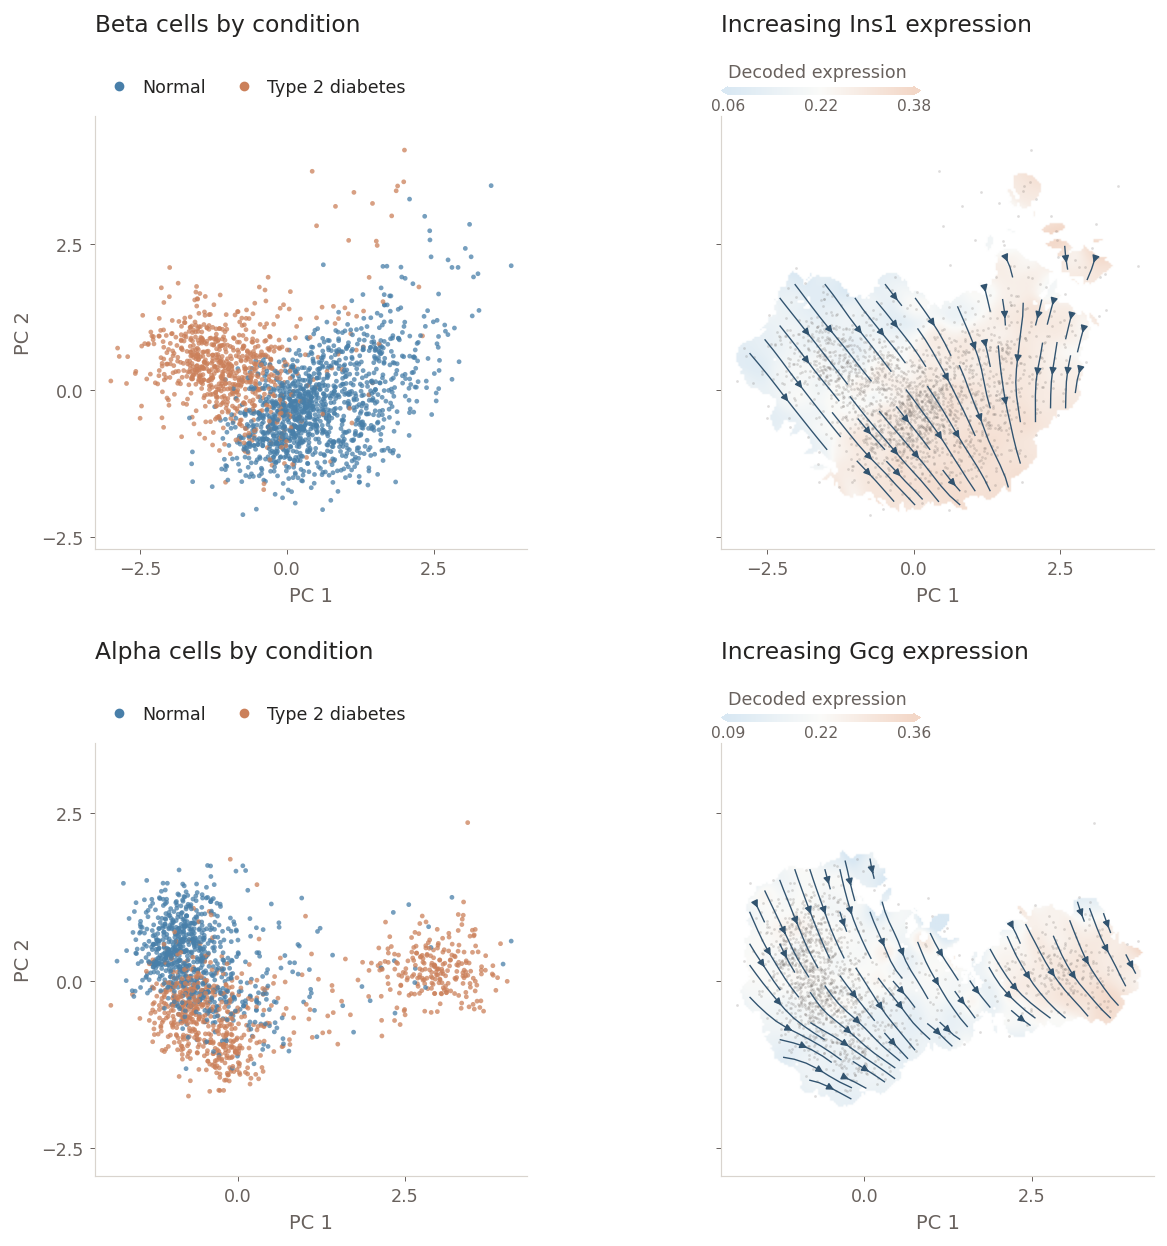

In [6]:
expression_cmap = LinearSegmentedColormap.from_list(
    'expression', ['#D9E8F3', '#FAFAF8', '#F3D7C7'],
)
expression_cmap.set_bad((1, 1, 1, 0))


def draw_streamlines(ax, xy, vectors, expression):
    bandwidth = .022 * np.ptp(xy, axis=0).max()
    x, y, u, v, background = smooth_field(xy, vectors, expression, gridsize=220, bandwidth=bandwidth)
    dx, dy = x[1] - x[0], y[1] - y[0]
    image = ax.imshow(background, origin='lower', interpolation='bilinear',
                      interpolation_stage='rgba', cmap=expression_cmap,
                      extent=(x[0] - dx/2, x[-1] + dx/2, y[0] - dy/2, y[-1] + dy/2),
                      norm=Normalize(*np.quantile(expression, [.02, .98])))
    speed = np.hypot(u, v)
    weak = speed < .03 * np.median(np.linalg.norm(vectors, axis=1))
    u, v = np.ma.masked_where(weak, u), np.ma.masked_where(weak, v)
    ax.streamplot(x, y, u, v, color='#31536F', density=1.0, linewidth=.7,
                  arrowsize=.75, minlength=.05, maxlength=.65, zorder=3)
    ax.scatter(*xy.T, s=2, color='#68615D', alpha=.22, linewidths=0, zorder=2)
    set_view(ax, xy)
    return image


def expression_bar(fig, image, ax):
    cax = ax.inset_axes([0, 1.05, .46, .018])
    cb = fig.colorbar(image, cax=cax, orientation='horizontal', extend='both', extendfrac=.035)
    cb.set_ticks(np.linspace(image.norm.vmin, image.norm.vmax, 3))
    cb.ax.xaxis.set_major_formatter('{x:.2f}')
    cb.ax.tick_params(labelsize=8, length=0, pad=2)
    cb.outline.set_visible(False)
    cax.set_title('Decoded expression', loc='left', fontsize=9, color='#68615D', pad=5)



fig, axes = plt.subplots(2, 2, figsize=(9, 9.4), sharex='row', sharey='row')
fig.subplots_adjust(left=.075, right=.98, bottom=.065, top=.87, wspace=.22, hspace=.45)
for row, (gene, ex) in enumerate(examples.items()):
    condition_ax, expression_ax = axes[row]
    draw_cells(condition_ax, ex['pca'], cells['disease'][ex['rows']])
    image = draw_streamlines(expression_ax, ex['pca'], ex['pca_vectors'], ex['expression'])
    condition_ax.set_title(f"{ex['label']} by condition", loc='left', y=1.17)
    expression_ax.set_title(f'Increasing {gene} expression', loc='left', y=1.17)
    condition_ax.legend(handles=disease_handles, loc='lower left', bbox_to_anchor=(0, 1.03),
                        ncol=2, fontsize=9, handletextpad=.3, columnspacing=1.2, borderaxespad=0)
    expression_bar(fig, image, expression_ax)
    for ax in axes[row]:
        ax.set(xlabel='PC 1')
    condition_ax.set_ylabel('PC 2')
plt.show()

## Genes aligned with the difference between populations

We use beta cells here. Let $a$ be the difference between the mean latent positions
of diabetic and normal cells. At normal cells, we score each gene by

$$
s_i = \frac{1}{N}\sum_{n=1}^{N}
\frac{\nabla y_i(z_n)^\mathsf{T}a}{\|\nabla y_i(z_n)\|\,\|a\|}.
$$

A positive score means that increasing the gene's predicted expression points
towards the diabetic group. At diabetic cells, we reverse the direction and ask
which gradients point towards the normal group.

We evaluate up to 256 cells per group. This example calculates the gradient norms
exactly; the original analysis estimated them from random directions.

In [7]:
ranking_cell_type = 'type B pancreatic cell'  # Change to 'pancreatic A cell' for alpha cells.
rank_n = 256
normal = np.flatnonzero((cells['cell_type'] == ranking_cell_type) & (cells['disease'] == disease_values[0]))
diabetic = np.flatnonzero((cells['cell_type'] == ranking_cell_type) & (cells['disease'] == disease_values[1]))
if not len(normal) or not len(diabetic):
    raise ValueError('Choose a cell type represented in both groups.')
direction = z[diabetic].mean(axis=0) - z[normal].mean(axis=0)

rankings = genes.copy()
for column, pool, axis in [
    ('normal_to_diabetic', normal, direction),
    ('diabetic_to_normal', diabetic, -direction),
]:
    rows = np.sort(np.random.RandomState(42).choice(pool, min(rank_n, len(pool)), replace=False))
    rankings[column] = mean_alignment(decoder, z[rows], cells['batches'][rows], axis)


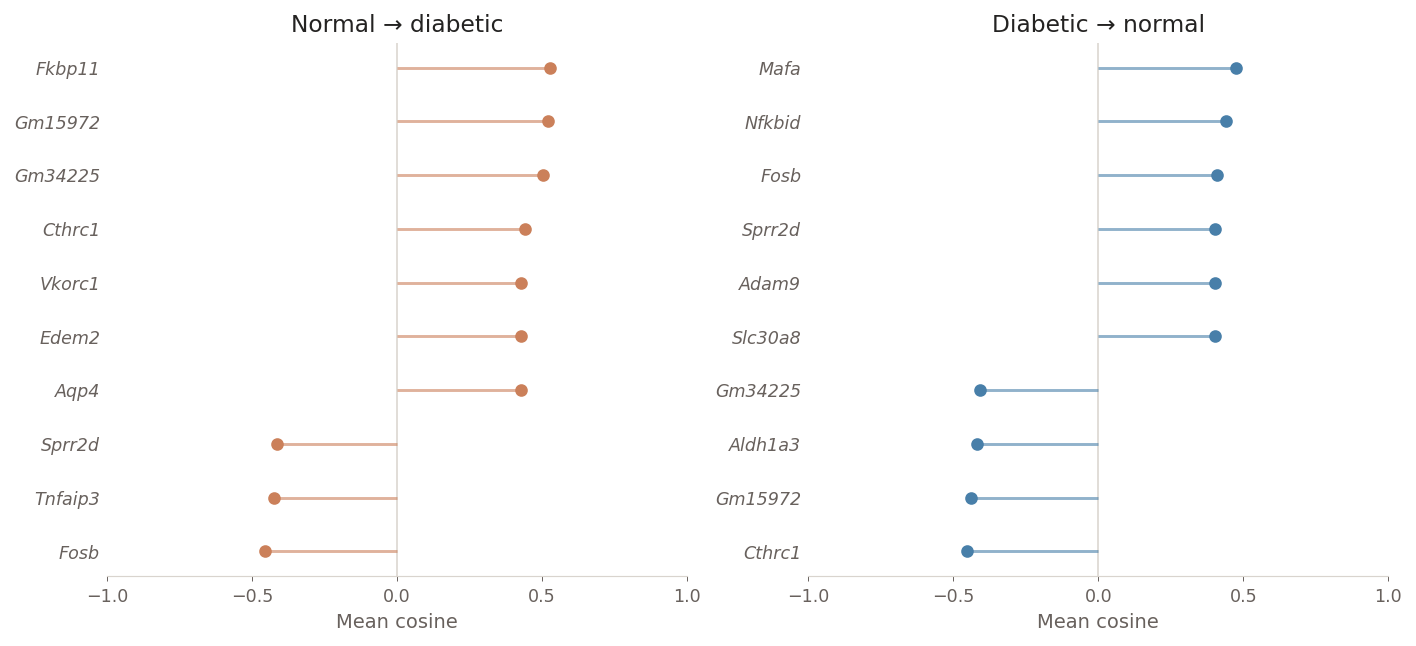

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout='constrained', sharex=True)
for ax, column, title, color in zip(
    axes, ['normal_to_diabetic', 'diabetic_to_normal'],
    ['Normal → diabetic', 'Diabetic → normal'], disease_colors[::-1],
):
    top = rankings.loc[rankings[column].abs().nlargest(10).index].sort_values(column)
    positions = np.arange(len(top))
    ax.axvline(0, color='#D9D4CE', linewidth=.8)
    ax.hlines(positions, 0, top[column], color=color, linewidth=1.5, alpha=.6)
    ax.scatter(top[column], positions, color=color, s=30, zorder=3)
    ax.set(yticks=positions, yticklabels=top['gene_name'], xlabel='Mean cosine',
           title=title, xlim=(-1, 1), xticks=[-1, -.5, 0, .5, 1])
    for tick in ax.get_yticklabels():
        tick.set_fontstyle('italic')
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', length=0)
plt.show()

Each panel shows the ten genes with the largest absolute score. A negative score
points against the direction named above that panel. The full rankings, with gene
identifiers, are in `rankings`.


## Brand new extension: gradients on UMAP

We use the same beta cells and Ins1 gradients as above. We fit UMAP once to their
latent representations and keep the coordinates fixed while projecting the
gradients. The settings are 80 neighbours, `min_dist=0.65` and a fixed random seed.

For each cell, neighbours whose latent displacement agrees with the gradient get
more weight. We subtract uniform weights and combine the neighbours' directions
in UMAP. This adapts the projection used for RNA velocity
([La Manno et al., 2018](https://doi.org/10.1038/s41586-018-0414-6);
[Bergen et al., 2020](https://doi.org/10.1038/s41587-020-0591-3)).
The lines describe decoder gradients, not estimates of RNA velocity.

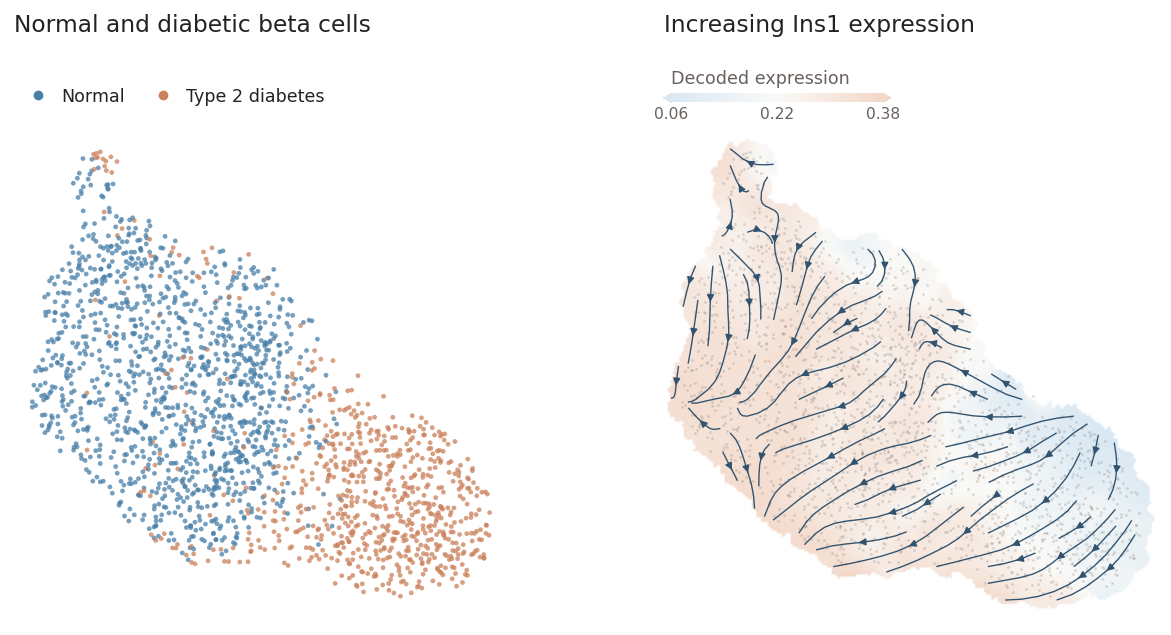

In [9]:
beta = examples['Ins1']
beta['umap'] = UMAP(n_neighbors=80, min_dist=.65, metric='euclidean',
                    random_state=0, n_jobs=1).fit_transform(z[beta['rows']])
beta['umap_vectors'] = project_gradients(z[beta['rows']], beta['gradients'], beta['umap'])

fig, axes = plt.subplots(1, 2, figsize=(9, 4.9))
fig.subplots_adjust(left=.03, right=.99, bottom=.02, top=.74, wspace=.16)
draw_cells(axes[0], beta['umap'], cells['disease'][beta['rows']])
image = draw_streamlines(axes[1], beta['umap'], beta['umap_vectors'], beta['expression'])
expression_bar(fig, image, axes[1])
axes[0].legend(handles=disease_handles, loc='lower left', bbox_to_anchor=(0, 1.03),
               ncol=2, fontsize=9, handletextpad=.3, columnspacing=1.2, borderaxespad=0)
for ax, title in zip(axes, ['Normal and diabetic beta cells', 'Increasing Ins1 expression']):
    ax.set_title(title, loc='left', y=1.17)
    ax.axis('off')
plt.show()